p(x) = (1-pi)delta/N(o,eps) + piN(o,sigma) --> HMC, Langevin, SMC

P(Y,X)=P(Y|X)P(X)=prod_T N(y_t|Ax_t,E)prod_T prod_D p(X) X(t-student low degree, spike and slab, horse)

1. Obtaining the matrix L (A of the model) from mne

In [1]:
import mne
import numpy as np
import pyvista
from jax.scipy.special import logsumexp
pyvista.set_jupyter_backend(None)
import jax
jax.config.update("jax_enable_x64", True)

In [2]:
montage = mne.channels.make_standard_montage("colin27_1020")
chs = [c for c in montage.ch_names if c not in ["T3", "T4", "T5", "T6"]]
info = mne.create_info(chs, sfreq=250.0, ch_types="eeg")
info.set_montage(montage)

<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, Fpz, Fp2, AF9, AF7, AF5, AF3, AF1, AFz, AF2, AF4, AF6, AF8, ...
 chs: 90 EEG
 custom_ref_applied: False
 dig: 93 items (3 Cardinal, 90 EEG)
 highpass: 0.0 Hz
 lowpass: 125.0 Hz
 meas_date: unspecified
 nchan: 90
 projs: []
 sfreq: 250.0 Hz
>

In [3]:
sphere = mne.make_sphere_model(r0="auto", head_radius="auto", info=info)
src = mne.setup_volume_source_space(
    sphere=sphere, pos=15.0, exclude=30.0, add_interpolator=False
)

Fitted sphere radius:         99.1 mm
Origin head coordinates:      -1.0 13.8 38.3 mm
Origin device coordinates:    -1.0 13.8 38.3 mm

Equiv. model fitting -> RV = 0.00347616 %%
mu1 = 0.944836    lambda1 = 0.136856
mu2 = 0.66776    lambda2 = 0.683695
mu3 = -0.291317    lambda3 = -0.0101806
Set up EEG sphere model with scalp radius    99.1 mm

Sphere                : origin at (-1.0 13.8 38.3) mm
              radius  : 89.2 mm
grid                  : 15.0 mm
mindist               : 5.0 mm
Exclude               : 30.0 mm

Setting up the sphere...
Surface CM = (  -1.0   13.8   38.3) mm
Surface fits inside a sphere with radius   89.2 mm
Surface extent:
    x =  -90.1 ...   88.2 mm
    y =  -75.3 ...  103.0 mm
    z =  -50.9 ...  127.4 mm
Grid extent:
    x = -105.0 ...   90.0 mm
    y =  -90.0 ...  105.0 mm
    z =  -60.0 ...  135.0 mm
2744 sources before omitting any.
840 sources after omitting infeasible sources not within 30.0 - 89.2 mm.
Source spaces are in MRI coordinates.
Checking t

In [4]:
fwd = mne.make_forward_solution(
    info, trans=None, src=src, bem=sphere, meg=False, eeg=True, mindist=5.0
)
L = fwd["sol"]["data"]

Source space          : <SourceSpaces: [<discrete, n_used=710>] MRI (surface RAS) coords, ~698 KiB>
MRI -> head transform : identity
Measurement data      : instance of Info
Sphere model      : origin at [-0.0009528   0.01381019  0.03826742] mm
Standard field computations
Do computations in head coordinates
Free source orientations

Read 1 source spaces a total of 710 active source locations

Coordinate transformation: MRI (surface RAS) -> head
    1.000000 0.000000 0.000000       0.00 mm
    0.000000 1.000000 0.000000       0.00 mm
    0.000000 0.000000 1.000000       0.00 mm
    0.000000 0.000000 0.000000       1.00

Read  90 EEG channels from info
Head coordinate coil definitions created.
Source spaces are now in head coordinates.

Using the sphere model.

Source spaces are in head coordinates.
Checking that the sources are inside the surface and at least    5.0 mm away (will take a few...)
Using the equivalent source approach in the homogeneous sphere for EEG
Computing EEG at 710 s

2. Set up the small simulation with only $x_1$ activated.

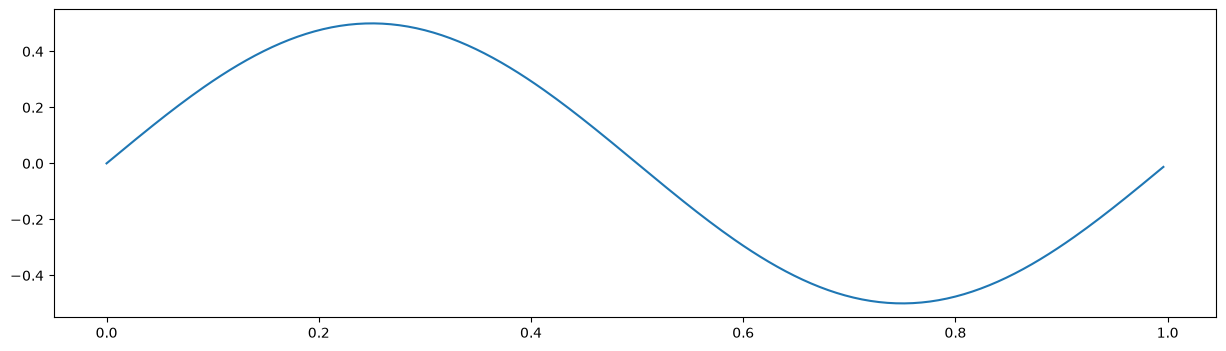

In [5]:
t = np.linspace(0, 1, int(info["sfreq"]), endpoint=False)
A = 0.5

# Signal of the first dipole
x_1 = A * np.sin(2 * np.pi * t)
X = np.zeros((L.shape[1], int(info["sfreq"])))
X[0] = x_1

# Plot the signal
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 4))
plt.plot(t, x_1)

3. "Forward" of the signal.

In [6]:
beta = 4
e = np.random.normal(0, 1/beta, size=(L.shape[0], int(info["sfreq"])))

In [7]:
Y = L @ X + e

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


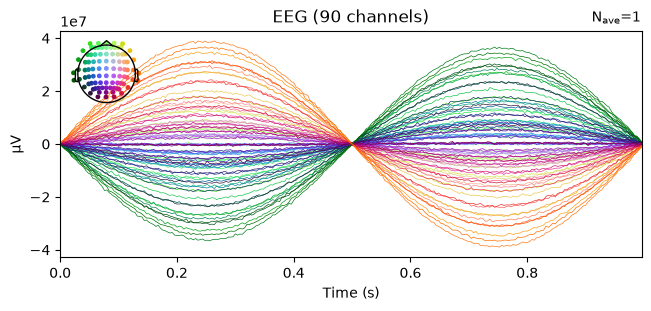

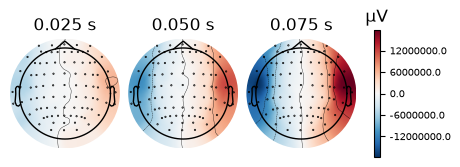

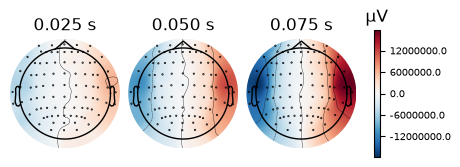

In [8]:
evoked = mne.EvokedArray(Y, info, tmin=0.0)
evoked.set_eeg_reference("average", projection=False)   # referencia promedio
evoked.plot(spatial_colors=True)
evoked.plot_topomap(times=[0.025, 0.05, 0.075])

4. Calculation and plot of the inverse solution using champagne algorithm.

In [9]:
from jax import random
from jax import grad
from jax import jit
from time import time
from jax.scipy.stats import multivariate_normal as mvn
import jax.numpy as jnp

In [10]:
class tStudentPrior:
    def __init__(self, df, scale):
        self.df = df
        self.scale = scale
        
    def log_prior(self, theta):
        """ Computes the log-prior of the t-Student distribution for a given parameter vector theta."""
        return -0.5 * (self.df + 1) * jnp.sum(jnp.log1p(theta**2 / (self.df * self.scale**2)), axis=-1)
    
    def sample_prior(self, key, num_samples, num_features):
        """ Samples from the t-Student prior distribution."""
        return random.t(key, df=self.df, shape=(num_samples, num_features)) * self.scale

df, scale = 6.0, 0.005
tStudent = tStudentPrior(df=df, scale=scale)

In [11]:
class SpikeAndSlabPrior:
    def __init__(self, slab_var, spike_var, slab_prob):
        self.slab_var = slab_var
        self.spike_var = spike_var
        self.slab_prob = slab_prob

    def log_prior(self, theta):
        """ Computes the log-prior of the spike-and-slab distribution for a given theta """
        ls = jnp.log(self.slab_prob)     - 0.5*jnp.log(2*jnp.pi*self.slab_var)  - theta**2/(2*self.slab_var)
        lp = jnp.log(1 - self.slab_prob) - 0.5*jnp.log(2*jnp.pi*self.spike_var) - theta**2/(2*self.spike_var)
        return jnp.sum(logsumexp(jnp.stack([ls, lp]), axis=0), axis=-1)
    
    def sample_prior(self, key, num_samples, num_features):
        """ Samples from the spike-and-slab prior distribution """
        slab_key, spike_key, mask_key = random.split(key, 3)
        slab_samples = random.normal(slab_key, shape=(num_samples, num_features)) * jnp.sqrt(self.slab_var)
        spike_samples = random.normal(spike_key, shape=(num_samples, num_features)) * jnp.sqrt(self.spike_var)
        mask = random.bernoulli(mask_key, p=self.slab_prob, shape=(num_samples, num_features))
        return mask * slab_samples + (1 - mask) * spike_samples
    
slab_var, spike_var, slab_prob = 0.1, 0.001, 0.5
SpikeAndSlab = SpikeAndSlabPrior(slab_var=slab_var, spike_var=spike_var, slab_prob=slab_prob)

In [12]:
class HorseShoePrior:
    def __init__(self, tau):
        self.tau = tau

    def log_prior(self, theta):
        """ Computes the log-prior of the horseshoe distribution for a given theta """
        pass
    
    def sample_prior(self, key, num_samples, num_features):
        """ Samples from the horseshoe prior distribution """
        pass
    
tau = 0.1
HorseShoe = HorseShoePrior(tau=tau)

In [13]:
class Posterior:
    def __init__(self, prior_distribution, L, Y, beta, y_tid):
        self.prior_distribution = prior_distribution
        self.L = L
        self.Y = Y
        self.beta = beta
        self.y_tid = y_tid

    def log_likelihood(self, theta):
        noise_prec = self.beta**2

        if theta.ndim == 1:  # MAP: shape (D,)
            residuals = self.y_tid - self.L @ theta
            return -0.5 * noise_prec * jnp.sum(residuals**2)

        # HMC: shape (N, D)
        residuals = self.y_tid[:, None] - self.L @ theta.T
        return -0.5 * noise_prec * jnp.sum(residuals**2, axis=0)

    def log_posterior(self, theta):
        return (
            self.prior_distribution.log_prior(theta)
            + self.log_likelihood(theta)
        )

    def log_likelihood_t(self, theta, t):
        noise_prec = self.beta**2

        if theta.ndim == 1:
            residuals = self.y_tid[:t] - self.L[:t, :] @ theta
            return -0.5 * noise_prec * jnp.sum(residuals**2)

        residuals = (
            self.y_tid[:t, None] - self.L[:t, :] @ theta.T
        )
        return -0.5 * noise_prec * jnp.sum(residuals**2, axis=0)


In [14]:
tid = 62
y_tid = Y[:, tid]
t_student_posterior = Posterior(prior_distribution=tStudent, L=L, Y=Y, beta=beta, y_tid=y_tid)
spike_and_slab_posterior = Posterior(prior_distribution=SpikeAndSlab, L=L, Y=Y, beta=beta, y_tid=y_tid)
horseshoe_posterior = Posterior(prior_distribution=HorseShoe, L=L, Y=Y, beta=beta, y_tid=y_tid)

#### MAP estimate

In [15]:
import jax

def objective(theta):
    return float(
        -t_student_posterior.log_posterior(
            jnp.asarray(theta)
        )
    )

def gradient(theta):
    grad_fn = jax.grad(
        lambda t: -t_student_posterior.log_posterior(t)
    )
    return np.asarray(
        grad_fn(jnp.asarray(theta)), dtype=float
    )

In [16]:
from scipy.optimize import minimize

theta0 = jnp.zeros(L.shape[1])

result = minimize(
    objective,
    x0=theta0,
    jac=gradient,
    method="L-BFGS-B"
)

print("MAP estimate:", result.x)

MAP estimate: [ 2.21293113e-03  3.38345890e-05 -1.87408705e-04 ...  3.90847150e-04
 -4.18746417e-05 -1.25770260e-03]


#### HMC

In [17]:
########################################################################################
# Energy functions
########################################################################################
def build_energy_functions(log_target):
    """ Helper function for constructing the relevant energy functions and gradients for HMC based on the given log_target function.
        The function log_target must accept JaX arrays of shape NxD, where D is the dimension of the parameter space and N
        is the number of points to be evaluated.
    """

    def kinetic_energy(nu):
        """ evaluates kinetic energy for momentum nu (shape: NxD), returns (N) array of kinetic energies"""
        N, D = nu.shape
        const = 0.5*D*jnp.log(2*jnp.pi) # can be left out
        return const + 0.5*jnp.sum(nu**2, 1).squeeze()
    
    def potential_energy(theta):
        """ evaluates potential energy for position theta (shape: NxD), returns (N) array of potential energies """
        return -log_target(theta).squeeze()
    
    def hamiltonian(theta, nu):
        """ evaluates Hamiltonian for state (theta, nu), returns (N) array of Hamiltonian values """
        return potential_energy(theta) + kinetic_energy(nu)
    
    return hamiltonian, potential_energy, kinetic_energy, grad(potential_energy)

In [18]:
def leapfrog(theta0, nu0, grad_pot_energy_fun, num_steps, step_size, full_trajectory=True):
    """ computes hamiltonian dynamics using leapfrog integration for D-dimensional problem

        Arguments:
        theta0                  --      Initial position, shape 1xD
        nu0                     --      Initial momentum, shape 1xD
        grad_pot_energy_fun     --      Function for evaluating the gradient of the potential energy, must be compatible with theta0
        num_steps               --      Number of leapfrog steps
        step_size               --      Step-size for integration, positive scalar
        full_trajectory         --      Flag indicating whether the function should return the full trajectory or only the last state.

        Returns:
        theta                   --      Final position after num_steps leapfrog steps
        nu                      --      Final momentum after num_steps leapfrog steps
        theta_trajectory        --      Array of position values for each step (shape: (num_steps+1) x D) if full_trajectory is True
        nu_trajectory           --      Array of momentum values for each step (shape: (num_steps+1) x D) if full_trajectory is True
    """

    if full_trajectory:
        theta_trajectory = [theta0]
        nus_trajectory = [nu0]
    
    theta, nu = theta0, nu0
    for k in range(num_steps):
        nu = nu - 0.5*step_size*grad_pot_energy_fun(theta)
        theta = theta + step_size*nu
        nu = nu - 0.5*step_size*grad_pot_energy_fun(theta)

        if full_trajectory:
            theta_trajectory.append(theta)
            nus_trajectory.append(nu)
            
    if full_trajectory:
        return theta, nu, jnp.vstack(theta_trajectory), jnp.vstack(nus_trajectory)
    else:
        return theta, nu

In [19]:
def HMC(log_target, num_iterations, theta0, num_leapfrog_steps=10, step_size=1e-1, seed=0):
    """ Implements the basic HMC algorithm for D-dimensional target distribution specified by log_target
    
    Arguments:
    log_target          -- Function implementing the logarithm of the target distribution (up to an additive constant). The function must return scalar values and be compatible with theta0
    num_iterations      -- Number of iterations
    theta0              -- Initial position, JaX array of shape 1xD, where D is the dimension
    num_leapfrog_steps  -- Number of leapfrog steps
    step_size           -- Step-size eta for leapfrog integration
    seed                -- seed

    Returns:
    thetas              -- MCMC samples, JaX array of shape (num_iterations+1, D)
    """
    hamiltonian, potential_energy, kinetic_energy, grad_pot_energy_fun = build_energy_functions(log_target)
    key = random.PRNGKey(seed)

    param_shape = theta0.shape
    theta = theta0
    thetas = [theta0]   # list of MCMC samples
    accept_count = 0    # for counting number of accepted samples
    t0 = time()

    # use just-in-time (jit) compilation to speed up computations - comment out if debugging becomes tricky
    hamiltonian = jit(hamiltonian)
    grad_pot_energy_fun = jit(grad_pot_energy_fun)

    for itt in range(num_iterations):        
        # update keys
        key, key_momentum, key_accept = random.split(key, 3)

        # resample momentum
        nu = random.normal(key_momentum, shape=param_shape)

        # propose
        theta_star, nu_star = leapfrog(theta, nu, grad_pot_energy_fun, num_leapfrog_steps, step_size, full_trajectory=False)

        # Compute log acceptance probability
        log_accept_prob = -hamiltonian(theta_star, nu_star) + hamiltonian(theta, nu)
    
        # accept/reject
        u = random.uniform(key_accept)
        if jnp.log(u) < log_accept_prob:
            theta = theta_star
            accept_count = accept_count + 1
 
        thetas.append(theta)

        # verbose
        if (itt+1) % int(num_iterations/10) == 0:
            print(f'Itt {itt+1:5d}/{num_iterations} ({100*(itt+1)/num_iterations:6.2f}%), accept_rate={accept_count/(itt+1):.3f}, time={time()-t0:3.2f}s')

    print(f'HMC done in {time()-t0:.3f}s with an avg. accept rate={accept_count/num_iterations:.3f}\n\n')

    return jnp.vstack(thetas)

In [20]:
theta0 = jnp.zeros((1, L.shape[1]))  # Initial position (zero vector)

thetas = HMC(log_target=spike_and_slab_posterior.log_posterior, num_iterations=3000, theta0=theta0, num_leapfrog_steps=250, step_size=1e-5, seed=0)
thetas_warmup = thetas[100:]  # Discard first 100 samples as warm-up
mean_estimate = jnp.mean(thetas_warmup, axis=0)

Itt   300/3000 ( 10.00%), accept_rate=0.973, time=16.14s
Itt   600/3000 ( 20.00%), accept_rate=0.977, time=30.93s
Itt   900/3000 ( 30.00%), accept_rate=0.980, time=45.52s
Itt  1200/3000 ( 40.00%), accept_rate=0.981, time=58.67s
Itt  1500/3000 ( 50.00%), accept_rate=0.980, time=71.78s
Itt  1800/3000 ( 60.00%), accept_rate=0.981, time=85.90s
Itt  2100/3000 ( 70.00%), accept_rate=0.983, time=99.72s
Itt  2400/3000 ( 80.00%), accept_rate=0.984, time=114.48s
Itt  2700/3000 ( 90.00%), accept_rate=0.984, time=129.30s
Itt  3000/3000 (100.00%), accept_rate=0.985, time=143.30s
HMC done in 143.306s with an avg. accept rate=0.985




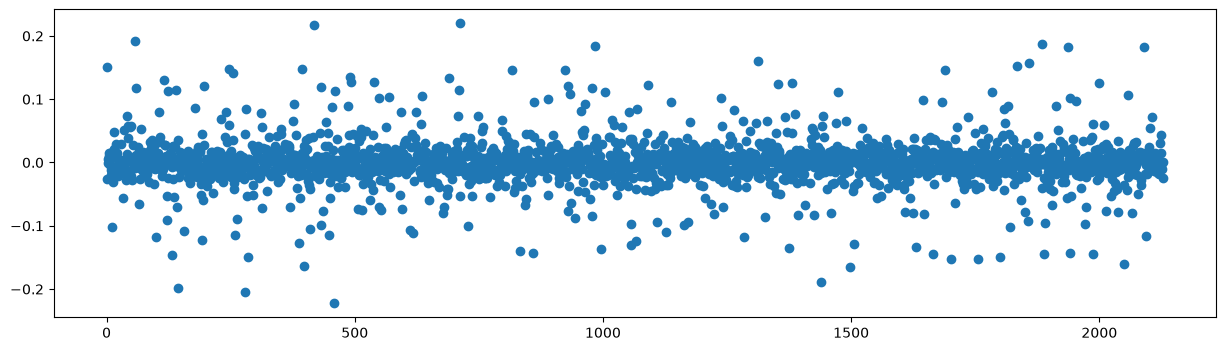

In [21]:
plt.figure(figsize=(15, 4))
plt.plot(mean_estimate, 'o', label='Mean Estimate')

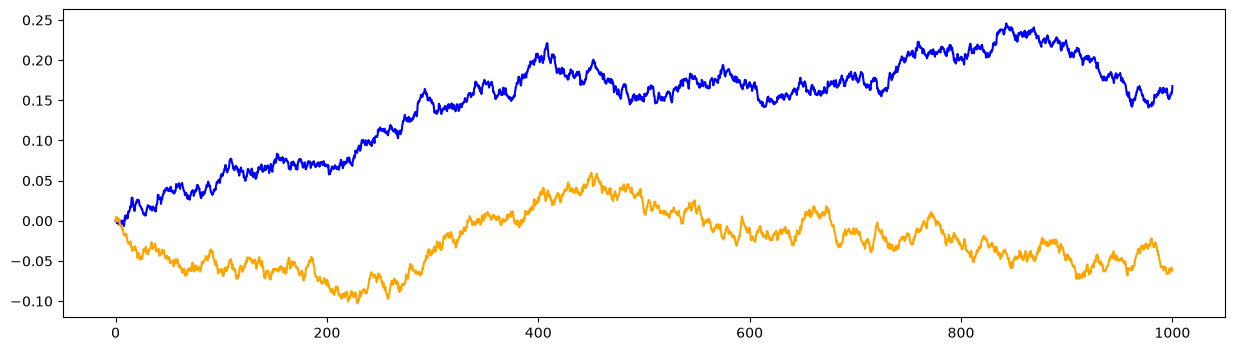

In [22]:
fig = plt.figure(figsize=(15, 4))
plt.plot(np.linspace(0, 1000, thetas.shape[0]), thetas[:, 0], label='Trace of x_0', color='blue')
plt.plot(np.linspace(0, 1000, thetas.shape[0]), thetas[:, 1], label='Trace of x_1', color='orange')

In [26]:
import contextlib, io

results_HMC = []
results_MAP = []

for size in range(2, X.shape[0]+1, 15):
    L_small = jnp.array(L[0:size, 0:size])
    x_small = X[0:size]
    Y = L_small @ x_small + e[0:size, :]
    y_tid = Y[:, tid]
    spike_and_slab_posterior = Posterior(prior_distribution=SpikeAndSlab, L=L_small, Y=Y, beta=beta, y_tid=y_tid)
    
    # MAP estimate
    def objective(theta):
        return float(
            -spike_and_slab_posterior.log_posterior(
                jnp.asarray(theta)
            )
        )
    def gradient(theta):
        grad_fn = jax.grad(
            lambda t: -spike_and_slab_posterior.log_posterior(t)
        )
        return np.asarray(
            grad_fn(jnp.asarray(theta)), dtype=float
        )
    
    theta0 = jnp.zeros(L_small.shape[1])
    result = minimize(
        objective,
        x0=theta0,
        jac=gradient,
        method="L-BFGS-B"
    )
    results_MAP.append({
        "size": size,
        "mean_estimate": result.x,
        "norm_diff": jnp.linalg.norm(result.x - x_small[:, tid]),
    })
    
    
    # HMC
    theta0 = jnp.zeros((1, L_small.shape[1]))  # Initial position (zero vector)
    with contextlib.redirect_stdout(io.StringIO()):
        thetas = HMC(log_target=spike_and_slab_posterior.log_posterior, num_iterations=2000, theta0=theta0, num_leapfrog_steps=250, step_size=1e-5, seed=0)
    thetas_warmup = thetas[100:]  # Discard first 100 samples as warm-up
    mean_estimate = jnp.mean(thetas_warmup, axis=0)
    results_HMC.append({
        "size": size,
        "mean_estimate": mean_estimate,
        "norm_diff": jnp.linalg.norm(mean_estimate - x_small[:, tid]),
        "thetas": thetas,
    })

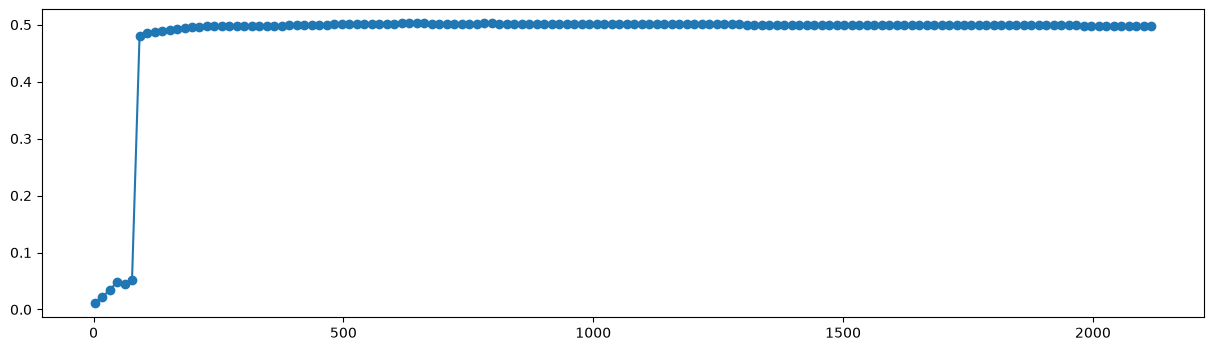

In [27]:
sizes_MAP = [r["size"] for r in results_MAP]
norm_diffs_MAP = [r["norm_diff"] for r in results_MAP]
plt.figure(figsize=(15, 4))
plt.plot(sizes_MAP, norm_diffs_MAP, 'o-', label='MAP Norm Difference')

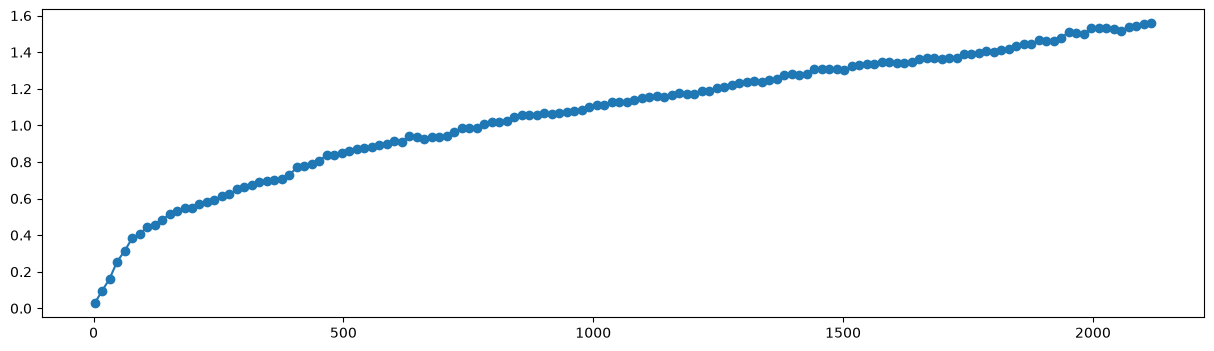

In [28]:
sizes = [res["size"] for res in results_HMC]
norm_diffs_HMC = [res["norm_diff"] for res in results_HMC]
plt.figure(figsize=(15, 4))
plt.plot(sizes, norm_diffs_HMC, 'o-', label='HMC Norm Difference')

In [29]:
# save results to a file
import pickle
with open("results.pkl", "wb") as f:
    pickle.dump({"results_HMC": results_HMC, "results_MAP": results_MAP}, f)

#### SMC

In [ ]:
tid = 62
y_tid = Y[:, tid]
t_student_posterior = Posterior(prior_distribution=tStudent, L=L, Y=Y, beta=beta, y_tid=y_tid)
spike_and_slab_posterior = Posterior(prior_distribution=SpikeAndSlab, L=L, Y=Y, beta=beta, y_tid=y_tid)
horseshoe_posterior = Posterior(prior_distribution=HorseShoe, L=L, Y=Y, beta=beta, y_tid=y_tid)

In [ ]:
import contextlib, io

def reweight(log_p_t, theta, itt):
    """ Computes the weights for the SMC algorithm based on the intermediate distribution p_t and the current samples theta and normalizes them.
    
    Arguments:
    p_t     -- Function implementing the logarithm of the intermediate distribution (up to an additive constant) at iteration itt. The function must return scalar values and be compatible with theta
    theta   -- Current samples, JaX array of shape NxD, where N is the number of samples and D is the dimension
    itt     -- Current iteration index

    Returns:
    weights -- Normalized weights for the current samples, JaX array of shape (N,)
    """
    log_weights = log_p_t(theta, itt) - log_p_t(theta, itt-1)  # Evaluate log of intermediate distribution at current samples
    weights = jnp.exp(log_weights - logsumexp(log_weights))  # Normalize the weights to sum to 1
    return weights

def SMC(log_prior, log_likelihood_t, theta0, num_iterations, S=10, num_leapfrog_steps=10, step_size=1e-1, seed=0):
    """ Implements the basic SMC algorithm for D-dimensional target distribution specified by log_target
    
    Arguments:
    log_prior           -- Function implementing the logarithm of the prior distribution (up to an additive constant). The function must return scalar values and be compatible with theta0
    log_likelihood_t    -- Function implementing the logarithm of the likelihood for a given time t. The function must return scalar values and be compatible with theta0
    theta0              -- Initial position, JaX array of shape 1xD, where D is the dimension
    num_iterations      -- Number of iterations
    S                   -- Number of steps in muatation step
    num_leapfrog_steps  -- Number of leapfrog steps
    step_size           -- Step-size eta for leapfrog integration
    seed                -- seed
    verbose             -- Whether to print progress information
    
    Returns:
    thetas              -- MCMC samples, JaX array of shape (num_iterations+1, D)
    """
    N = theta0.shape[0]  # Number of particles
    key = random.PRNGKey(seed)
    theta, thetas = theta0, [theta0]   # list of SMC samples
    
    weights = jnp.ones(N) / N  # Initialize weights uniformly
    
    for itt in range(1, num_iterations + 1):        
        # Resampling step
        key, key_resample = random.split(key)
        indices = random.choice(key_resample, a=N, shape=(N,), p=weights)
        # For indices keep thetas, for the rest 
        theta = theta[indices]
    
        # Mutation step using HMC
        log_target_t = lambda theta: log_prior(theta) + log_likelihood_t(theta, itt)
        new = []
        with contextlib.redirect_stdout(io.StringIO()):
            for i in range(N):
                theta_i = theta[i:i+1]  # Current particle
                chain = HMC(log_target_t, S, theta_i, num_leapfrog_steps, step_size, seed=seed + itt * N + i)  # Take the last sample from HMC as the new theta
                new.append(chain[-1])  # Append the last sample of the chain to new particles
        theta = jnp.vstack(new)  # Stack the new particles into a single array
        thetas.append(theta)
        
        # Reweighing step
        weights = reweight(log_likelihood_t, theta, itt)
            
    return thetas

N sim to D
Lnd ~N(0,I)

In [ ]:
# Sample from prior
N = Y.shape[0]  # Number of particles equal to the number of observations
theta0 = spike_and_slab_posterior.prior_distribution.sample_prior(random.PRNGKey(0), num_samples=N, num_features=L.shape[1])

lambdas = jnp.concatenate([jnp.zeros(1), jnp.geomspace(1e-9, 1, Y.shape[0])])
tempered_lik = lambda theta, t: lambdas[t] * spike_and_slab_posterior.log_likelihood(theta)

thetas = SMC(log_prior=spike_and_slab_posterior.prior_distribution.log_prior, log_likelihood_t=tempered_lik, num_iterations=Y.shape[0], theta0=theta0, S=10, num_leapfrog_steps=10, step_size=1e-5, seed=0)

final_particles = thetas[-1]  # Final samples after SMC
mean_estimate = jnp.mean(final_particles, axis=0)

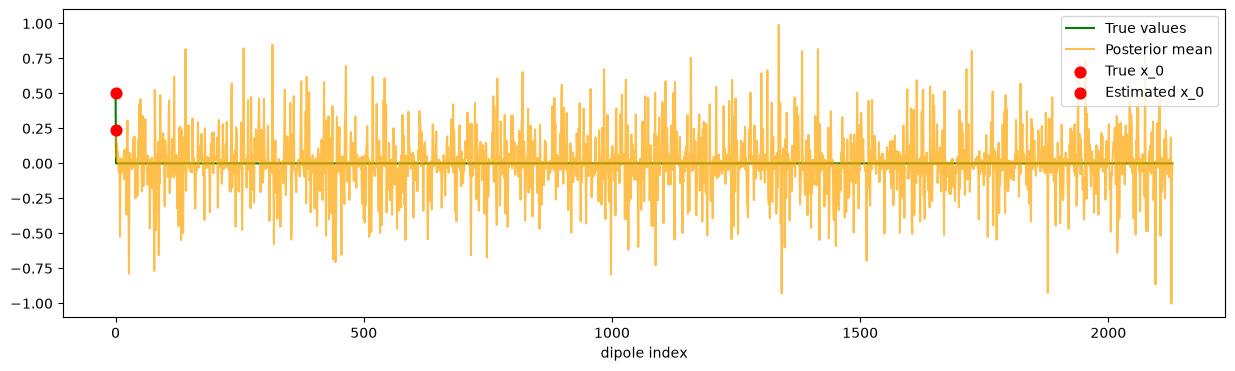

In [ ]:
idx = np.arange(L.shape[1])                      

fig = plt.figure(figsize=(15, 4))
real = np.zeros(L.shape[1]); real[0] = 0.5
plt.plot(idx, real, label='True values', color='green')
plt.plot(idx, mean_estimate, label='Posterior mean', color='orange', alpha=0.7)

plt.scatter([0], [real[0]], color='red', s=60, zorder=3, label='True x_0')
plt.scatter([0], [mean_estimate[0]], color='red', s=60, zorder=3, label='Estimated x_0')

plt.xlabel('dipole index'); plt.legend()

In [ ]:
X.shape

(2130, 250)

In [ ]:
# N sim to D with L_{n,l} ~ N(0, I)
L = random.normal(random.PRNGKey(0), shape=(e.shape[0], X.shape[0]))
Y = L @ X + e
y_tid = Y[:, tid]
t_student_posterior = Posterior(prior_distribution=tStudent, L=L, Y=Y, beta=beta, y_tid=y_tid)
spike_and_slab_posterior = Posterior(prior_distribution=SpikeAndSlab, L=L, Y=Y, beta=beta, y_tid=y_tid)
horseshoe_posterior = Posterior(prior_distribution=HorseShoe, L=L, Y=Y, beta=beta, y_tid=y_tid)

In [ ]:
# Sample from prior
N = Y.shape[0]  # Number of particles equal to the number of observations
theta0 = spike_and_slab_posterior.prior_distribution.sample_prior(random.PRNGKey(0), num_samples=N, num_features=L.shape[1])

lambdas = jnp.concatenate([jnp.zeros(1), jnp.geomspace(1e-9, 1, Y.shape[0])])
tempered_lik = lambda theta, t: lambdas[t] * spike_and_slab_posterior.log_likelihood(theta)

thetas = SMC(log_prior=spike_and_slab_posterior.prior_distribution.log_prior, log_likelihood_t=tempered_lik, num_iterations=Y.shape[0], theta0=theta0, S=10, num_leapfrog_steps=10, step_size=1e-5, seed=0)

final_particles = thetas[-1]  # Final samples after SMC
mean_estimate = jnp.mean(final_particles, axis=0)

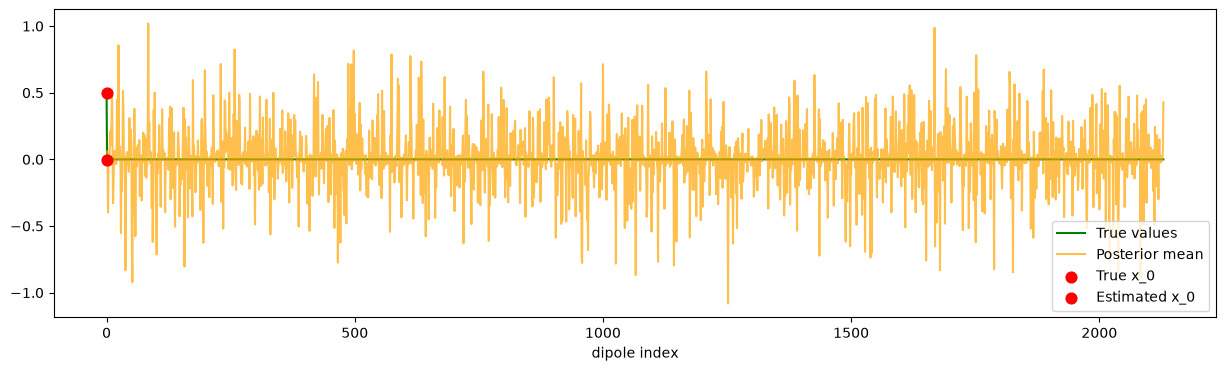

In [ ]:
idx = np.arange(L.shape[1])                      

fig = plt.figure(figsize=(15, 4))
real = np.zeros(L.shape[1]); real[0] = 0.5
plt.plot(idx, real, label='True values', color='green')
plt.plot(idx, mean_estimate, label='Posterior mean', color='orange', alpha=0.7)

plt.scatter([0], [real[0]], color='red', s=60, zorder=3, label='True x_0')
plt.scatter([0], [mean_estimate[0]], color='red', s=60, zorder=3, label='Estimated x_0')

plt.xlabel('dipole index'); plt.legend()

5. Evaluation

In [30]:
def f1_score(X, X_hat, threshold_activated=1e-5):
    """
    Compute the F1 score for the estimated source variances.
    
    Parameters
    ----------
    X : array-like, shape (n_dipoles, n_timepoints)
        The true source signals over time.
    X_hat : array-like, shape (n_dipoles, n_timepoints)
        The estimated source signals over time.
    Returns
    -------s
    f1 : float
        The F1 score for the estimated source variances.
    """
    # Identify activated dipoles based on the estimated source signals
    activated_estimated = np.where(np.var(X_hat, axis=1) > threshold_activated)[0]
    
    # Identify activated dipoles based on the true source signals
    activated_true = np.where(np.var(X, axis=1) > threshold_activated)[0]
    
    # Compute true positives, false positives, and false negatives
    tp = len(set(activated_estimated) & set(activated_true))
    fp = len(set(activated_estimated) - set(activated_true))
    fn = len(set(activated_true) - set(activated_estimated))
    
    # Compute precision and recall
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Compute F1 score
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    return f1

In [31]:
for r in results_HMC:
    f1 = f1_score(X[:r["size"], :], r["mean_estimate"][:, None])
    r["f1_score"] = f1

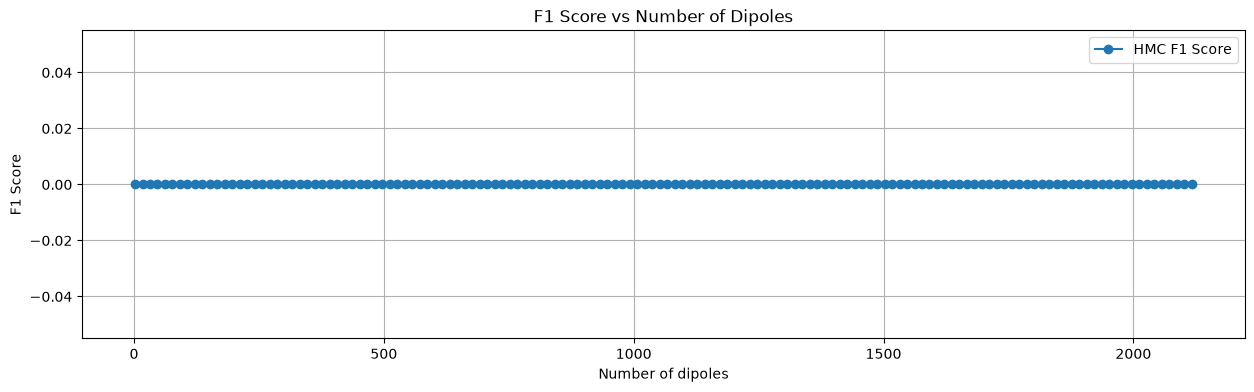

In [32]:
# plot f1 scores
sizes = [r["size"] for r in results_HMC]
f1_scores = [r["f1_score"] for r in results_HMC]
plt.figure(figsize=(15, 4))
plt.plot(sizes, f1_scores, 'o-', label='HMC F1 Score')
plt.xlabel('Number of dipoles'); plt.ylabel('F1 Score'); plt.title('F1 Score vs Number of Dipoles'); plt.legend(); plt.grid()

64 bits, investigar traza 42, reestructurar codigo